<div style="background:#1D366A;border-radius:12px;padding:22px 28px;font-family:Calibri,Segoe UI,sans-serif;">
  <div style="display:flex;align-items:center;">
    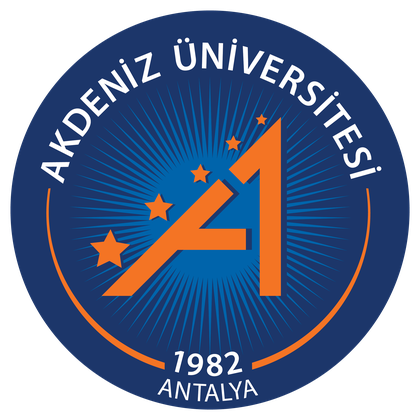
    <div>
      <div style="font-size:13px;font-weight:bold;letter-spacing:1.5px;color:#FFFFFF;">AKDENİZ UNIVERSITY &nbsp;·&nbsp; FACULTY OF ENGINEERING</div>
      <div style="font-size:12.5px;color:#C9D6EA;">Optimization Theory &amp; Applications</div>
    </div>
  </div>
  <div style="font-size:13px;font-weight:bold;letter-spacing:3px;color:#F47524;margin-top:16px;">WEEK 1 · LAB</div>
  <div style="font-size:30px;font-weight:bold;color:#FFFFFF;margin-top:1px;">Seeing Optimization in Python</div>
  <div style="font-size:15px;color:#C9D6EA;margin-top:6px;">NumPy · Matplotlib · SciPy — objective functions, surfaces, contours &amp; feasible regions</div>
</div>

### Welcome to the lab 👋

In the lecture we met the **anatomy of an optimization problem** — decision variables, an objective, and constraints — and the difference between **local** and **global** optima. This lab makes those ideas *tangible*: you will define objective functions in Python, **see** them as surfaces and contour plots, draw a **feasible region**, and call a real solver.

**By the end you will be able to**
- represent points, objectives, and constraints as **NumPy** arrays;
- define an objective `f(x)` as a Python function and approximate its **gradient**;
- visualize objectives in **1-D and 2-D** (curves, contours, 3-D surfaces) with **Matplotlib**;
- shade a 2-D **feasible region** from linear constraints;
- find a minimum with **`scipy.optimize.minimize`**.

**How to use this notebook** — run each cell with **Shift + Enter**, read the explanations, and complete the *🧪 Your turn* tasks at the end. Everything is styled in the course's Akdeniz theme.

<div style="border-left:5px solid #F47524;padding:2px 0 2px 12px;margin:10px 0 4px;"><div style="color:#F47524;font-weight:bold;letter-spacing:2px;font-size:12px;font-family:Calibri,Segoe UI,sans-serif;">Section 0</div><div style="color:#0E1A33;font-weight:bold;font-size:23px;font-family:Calibri,Segoe UI,sans-serif;">Setup &amp; course style</div></div>

Import our tools and apply the **Akdeniz plot style** so every figure matches the course identity. *(The canonical style lives in `akdeniz-brand/akdeniz_style.py`; we inline it here so this notebook is self-contained.)*

In [ ]:
# --- Imports --------------------------------------------------------------
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from scipy.optimize import minimize
%matplotlib inline

# --- Akdeniz course palette + matplotlib style ----------------------------
AK = {"navy":"#0E1A33", "navy2":"#1D366A", "blue":"#0063AA", "blue_l":"#5B9BD5",
      "orange":"#F47524", "peach":"#FDCBA8", "slate":"#2A3654", "mute":"#6B7591",
      "grid":"#D6DBE5", "red":"#C0481B"}

def apply_style():
    plt.rcParams.update({
        "figure.facecolor": "white", "savefig.facecolor": "white", "figure.dpi": 110,
        "font.size": 12, "axes.titleweight": "bold", "axes.titlecolor": AK["navy"],
        "axes.titlesize": 14, "axes.labelcolor": AK["slate"], "axes.edgecolor": AK["mute"],
        "axes.linewidth": 1.1, "axes.grid": True, "axes.axisbelow": True,
        "axes.spines.top": False, "axes.spines.right": False,
        "grid.color": AK["grid"], "grid.linewidth": 0.7,
        "xtick.color": AK["mute"], "ytick.color": AK["mute"], "text.color": AK["slate"],
        "legend.frameon": False,
        "axes.prop_cycle": plt.cycler(color=[AK["navy2"], AK["orange"], AK["blue"], AK["red"], AK["blue_l"]]),
    })

apply_style()
AKMAP = LinearSegmentedColormap.from_list("akdeniz",
            [AK["navy"], AK["blue"], AK["blue_l"], AK["peach"], AK["orange"]])

import scipy
print("NumPy", np.__version__, "| SciPy", scipy.__version__)
print("Akdeniz style applied ✓")

<div style="border-left:5px solid #F47524;padding:2px 0 2px 12px;margin:10px 0 4px;"><div style="color:#F47524;font-weight:bold;letter-spacing:2px;font-size:12px;font-family:Calibri,Segoe UI,sans-serif;">Section 1</div><div style="color:#0E1A33;font-weight:bold;font-size:23px;font-family:Calibri,Segoe UI,sans-serif;">NumPy warm-up — the language of optimization</div></div>

Optimization lives in **vectors and matrices**. In NumPy a decision vector, the objective coefficients, and a constraint matrix are all just arrays — and we operate on them *without writing loops*.

In [ ]:
# A tiny linear program in array form:
#   maximize  c·x      subject to   A x <= b,   x >= 0
x = np.array([3.0, 1.0])              # a candidate decision vector  (x1, x2)
c = np.array([3.0, 4.0])              # objective coefficients
A = np.array([[1.0, 1.0],             # constraint matrix
              [1.0, 3.0]])
b = np.array([4.0, 6.0])              # right-hand sides

print("objective  c · x      =", c @ x)            # dot product
print("A x                =", A @ x)                    # matrix-vector product
print("A x <= b ?         =", A @ x <= b)               # elementwise comparison
print("feasible (all)?    =", np.all(A @ x <= b) and np.all(x >= 0))
print("Euclidean norm ||x|| =", np.linalg.norm(x))

<div style="background:#EAF1F8;border-left:5px solid #0063AA;padding:9px 14px;border-radius:4px;margin:6px 0;"><b style="color:#0063AA;">💡 Tip&nbsp;&nbsp;</b>The <code>@</code> operator is matrix multiplication. <code>np.all(...)</code> collapses a boolean array to a single True/False — perfect for &ldquo;are <i>all</i> constraints satisfied?&rdquo;</div>

In [ ]:
# Evaluate a function over a whole GRID at once (vectorized — no loops).
f = lambda x, y: x**2 + y**2          # a simple bowl  f(x, y) = x^2 + y^2
xs = np.linspace(-2, 2, 5)
ys = np.linspace(-2, 2, 5)
X, Y = np.meshgrid(xs, ys)            # two 5x5 coordinate grids
print("grid shape:", X.shape)
print("f on the grid:\n", np.round(f(X, Y), 1))

<div style="border-left:5px solid #F47524;padding:2px 0 2px 12px;margin:10px 0 4px;"><div style="color:#F47524;font-weight:bold;letter-spacing:2px;font-size:12px;font-family:Calibri,Segoe UI,sans-serif;">Section 2</div><div style="color:#0E1A33;font-weight:bold;font-size:23px;font-family:Calibri,Segoe UI,sans-serif;">Objectives as Python functions &amp; their gradients</div></div>

The objective $f_0(x)$ from the standard form is just a Python callable. Many algorithms also need the **gradient** $\nabla f$. When we don't have it in closed form, we can approximate it with **finite differences**.

In [ ]:
def f_bowl(p):
    """Convex quadratic bowl  f(x, y) = x^2 + y^2  (global min at the origin)."""
    x, y = p
    return x**2 + y**2

def numerical_gradient(func, p, h=1e-5):
    """Approximate the gradient of `func` at point `p` by central differences."""
    p = np.asarray(p, dtype=float)
    g = np.zeros_like(p)
    for i in range(p.size):
        step = np.zeros_like(p); step[i] = h
        g[i] = (func(p + step) - func(p - step)) / (2 * h)
    return g

p0 = np.array([1.5, -1.0])
print("f(p0)        =", f_bowl(p0))
print("numeric grad =", np.round(numerical_gradient(f_bowl, p0), 5))
print("exact grad   = [2x, 2y] =", [2*p0[0], 2*p0[1]])

<div style="border-left:5px solid #F47524;padding:2px 0 2px 12px;margin:10px 0 4px;"><div style="color:#F47524;font-weight:bold;letter-spacing:2px;font-size:12px;font-family:Calibri,Segoe UI,sans-serif;">Section 3</div><div style="color:#0E1A33;font-weight:bold;font-size:23px;font-family:Calibri,Segoe UI,sans-serif;">1-D picture — local vs. global minima</div></div>

A bumpy 1-D function has several **local** minima but only one **global** minimum. A method that just &ldquo;rolls downhill&rdquo; can get stuck in the wrong valley — the central difficulty we discussed in lecture.

In [ ]:
def g(x):
    return np.sin(x) + 0.5*np.sin(2.5*x) + 0.08*x**2

xx = np.linspace(-8, 8, 1000)
yy = g(xx)

# find local minima by a simple discrete check, then the global one
mins = [i for i in range(1, len(xx)-1) if yy[i] < yy[i-1] and yy[i] < yy[i+1]]
gi = min(mins, key=lambda i: yy[i])

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(xx, yy, color=AK["navy2"], lw=2.4)
for i in mins:
    ax.plot(xx[i], yy[i], "o", mfc="white", mec=AK["blue"], mew=2, ms=9)
ax.plot(xx[gi], yy[gi], "*", color=AK["orange"], mec=AK["navy"], mew=0.8, ms=22)
ax.annotate("global minimum", (xx[gi], yy[gi]), xytext=(20, 34), textcoords="offset points",
            color=AK["orange"], fontweight="bold",
            arrowprops=dict(arrowstyle="-|>", color=AK["orange"]))
ax.set(title="Local vs. global minima", xlabel="x", ylabel="g(x)")
plt.show()

print(f"global minimum near x = {xx[gi]:.2f},  g = {yy[gi]:.3f}")
print(f"number of local minima found: {len(mins)}")

<div style="border-left:5px solid #F47524;padding:2px 0 2px 12px;margin:10px 0 4px;"><div style="color:#F47524;font-weight:bold;letter-spacing:2px;font-size:12px;font-family:Calibri,Segoe UI,sans-serif;">Section 4</div><div style="color:#0E1A33;font-weight:bold;font-size:23px;font-family:Calibri,Segoe UI,sans-serif;">2-D picture — contours &amp; objective surfaces</div></div>

In two variables we can *see* the whole objective: as a 3-D **surface** and as a 2-D **contour** (level-set) map. We use the famous **Rosenbrock** function $f(x,y)=(1-x)^2+100(y-x^2)^2$ — its curved valley makes it a classic optimization stress-test (global minimum at $(1,1)$).

In [ ]:
def rosenbrock(x, y):
    return (1 - x)**2 + 100*(y - x**2)**2

xs = np.linspace(-2, 2, 300)
ys = np.linspace(-1, 3, 300)
X, Y = np.meshgrid(xs, ys)
Z = np.log10(rosenbrock(X, Y) + 1)        # log scale so the valley is visible

fig = plt.figure(figsize=(11, 4.2))

ax1 = fig.add_subplot(1, 2, 1, projection="3d")
ax1.plot_surface(X, Y, Z, cmap=AKMAP, linewidth=0, antialiased=True)
ax1.set_title("Objective surface (log scale)")
ax1.set_xlabel("x"); ax1.set_ylabel("y")
ax1.view_init(elev=42, azim=-58)

ax2 = fig.add_subplot(1, 2, 2)
ax2.contourf(X, Y, Z, levels=40, cmap=AKMAP)
ax2.contour(X, Y, Z, levels=12, colors="white", linewidths=0.4, alpha=0.35)
ax2.plot(1, 1, "*", color="white", mec=AK["navy"], ms=18)
ax2.annotate("global min (1, 1)", (1, 1), xytext=(-10, 12), textcoords="offset points",
             ha="right", color="white", fontweight="bold")
ax2.set(title="Contour view", xlabel="x", ylabel="y")
ax2.grid(False)
plt.tight_layout(); plt.show()

<div style="background:#EAF1F8;border-left:5px solid #0063AA;padding:9px 14px;border-radius:4px;margin:6px 0;"><b style="color:#0063AA;">💡 Tip&nbsp;&nbsp;</b><code>contourf</code> fills the level sets; <code>contour</code> draws the lines. Points on one contour all share the same objective value — like elevation lines on a map.</div>

<div style="border-left:5px solid #F47524;padding:2px 0 2px 12px;margin:10px 0 4px;"><div style="color:#F47524;font-weight:bold;letter-spacing:2px;font-size:12px;font-family:Calibri,Segoe UI,sans-serif;">Section 5</div><div style="color:#0E1A33;font-weight:bold;font-size:23px;font-family:Calibri,Segoe UI,sans-serif;">Drawing a feasible region</div></div>

Constraints carve a **feasible region** out of the plane. Here we reproduce the lecture's linear program and shade the region where *all* constraints hold, overlay the **objective contours**, and mark the optimal **vertex**.

$$\text{maximize } 3x_1 + 4x_2 \quad\text{s.t.}\quad x_1+x_2\le 4,\;\; x_1+3x_2\le 6,\;\; x_1,x_2\ge 0$$

In [ ]:
from matplotlib.patches import Polygon

verts = [(0, 0), (4, 0), (3, 1), (0, 2)]      # corners of the feasible polygon
fig, ax = plt.subplots(figsize=(5.8, 5.0))
ax.add_patch(Polygon(verts, closed=True, facecolor=AK["blue"], alpha=0.15,
                     edgecolor=AK["blue"], lw=2))

t = np.linspace(-0.5, 5.2, 100)
ax.plot(t, 4 - t,       color=AK["navy2"], lw=1.7)     # x1 + x2 = 4
ax.plot(t, (6 - t) / 3, color=AK["blue"],  lw=1.7)     # x1 + 3 x2 = 6
ax.axhline(0, color=AK["mute"], lw=1); ax.axvline(0, color=AK["mute"], lw=1)

for cval in (4, 8, 13, 17):                            # objective level sets
    ax.plot(t, (cval - 3*t) / 4, "--", color=AK["orange"], lw=1.1, alpha=0.85)

ax.plot(3, 1, "*", color=AK["orange"], mec=AK["navy"], mew=0.8, ms=22)
ax.annotate("optimum (3, 1)", (3, 1), xytext=(10, -20), textcoords="offset points",
            fontweight="bold", color=AK["slate"])
ax.text(0.9, 0.45, "feasible\nregion", color=AK["blue"], fontweight="bold", ha="center")
ax.set(title="A 2-D feasible region", xlabel="x₁", ylabel="x₂",
       xlim=(-0.4, 5.2), ylim=(-0.4, 4.3))
ax.grid(True)
plt.show()

# An LP optimum is always at a vertex — so just check the corners:
objective = lambda v: 3*v[0] + 4*v[1]
best = max(verts, key=objective)
print("objective at each vertex:", {v: objective(v) for v in verts})
print("best vertex:", best, "-> objective =", objective(best))

<div style="border-left:5px solid #F47524;padding:2px 0 2px 12px;margin:10px 0 4px;"><div style="color:#F47524;font-weight:bold;letter-spacing:2px;font-size:12px;font-family:Calibri,Segoe UI,sans-serif;">Section 6</div><div style="color:#0E1A33;font-weight:bold;font-size:23px;font-family:Calibri,Segoe UI,sans-serif;">A peek ahead — calling a real solver</div></div>

We will *build* optimization algorithms later in the course. For now, meet **`scipy.optimize.minimize`** — give it an objective and a starting point and it returns the minimizer. (Note: it *minimizes*, so to maximize you minimize the negative.)

In [ ]:
# 1) the convex bowl — easy, converges to the origin
res_bowl = minimize(f_bowl, x0=[1.5, -1.0])
print("bowl       ->  x* =", np.round(res_bowl.x, 4), " f* =", round(res_bowl.fun, 6))

# 2) Rosenbrock — the curved valley makes it much harder
rosen = lambda p: (1 - p[0])**2 + 100*(p[1] - p[0]**2)**2
res_r = minimize(rosen, x0=[-1.2, 1.0], method="BFGS")
print("Rosenbrock ->  x* =", np.round(res_r.x, 4),
      " f* =", round(float(res_r.fun), 6), " iterations =", res_r.nit)
print("success:", res_r.success)

<div style="background:#EAF1F8;border-left:5px solid #0063AA;padding:9px 14px;border-radius:4px;margin:6px 0;"><b style="color:#0063AA;">💡 Tip&nbsp;&nbsp;</b>Try other methods via <code>method="Nelder-Mead"</code> or <code>"Powell"</code>. Different problem <i>classes</i> call for different algorithms — exactly the theme of the course.</div>

<div style="border-left:5px solid #F47524;padding:2px 0 2px 12px;margin:10px 0 4px;"><div style="color:#F47524;font-weight:bold;letter-spacing:2px;font-size:12px;font-family:Calibri,Segoe UI,sans-serif;">Your turn</div><div style="color:#0E1A33;font-weight:bold;font-size:23px;font-family:Calibri,Segoe UI,sans-serif;">Exercises</div></div>

Work through these in new cells below. They reinforce today's lecture and set up **HW 0**.

1. **Re-solve the LP.** Change the objective to **maximize $x_1 + 2x_2$** over the same feasible region. Evaluate it at each vertex (reuse `verts`) to find the new optimum. *Which constraint(s) are active at the solution?*

2. **Gradient descent by hand.** Using `numerical_gradient`, implement the update $x_{k+1} = x_k - \alpha\,\nabla f(x_k)$ for `f_bowl`, starting from $(1.8, 1.6)$. Store the iterates and plot the path on a contour of the bowl. Try step sizes $\alpha = 0.05,\ 0.3,\ 0.8$ — describe what happens (convergence, slow, oscillation/divergence).

3. **Model & solve a CE problem.** From lecture, the *circuit-energy* model is
   $\min \sum_i C_i v_i^2$ s.t. a delay budget and bounds $v_{\min}\le v_i\le v_{\max}$.
   Pick small numbers (e.g. 3 gates) and minimize it with `scipy.optimize.minimize` using the `bounds=` and `constraints=` arguments.

4. **(Stretch) Method matters.** Minimize Rosenbrock from the hard start $(-1.2, 1.0)$ with `"Nelder-Mead"` and with `"BFGS"`. Compare `res.nit` and `res.nfev`. Why might a gradient-based method win here?

---
<div style="color:#6B7591;font-family:Calibri,Segoe UI,sans-serif;font-size:13px;">
<b style="color:#0E1A33;">Wrap-up.</b> You can now turn an objective into code, see it as a surface/contour, draw a feasible region, and call a solver — the toolkit we use all term.
&nbsp;·&nbsp; <b style="color:#F47524;">Next week:</b> Mathematical Foundations — gradients, Hessians, and convex sets &amp; functions.
<br>Optimization Theory &amp; Applications · Akdeniz University · Faculty of Engineering
</div>